In [1]:
from scipy import fftpack
from scipy import signal
import scipy.io.wavfile
from scipy import io
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl

simulated signal with pure sinusoidal 
components at 1 Hz and at 22 Hz

In [47]:
def signal_samples(t):
    return (
        2 * np.sin(2 * np.pi * t)
        + 3 * np.sin(22 * 2 * np.pi * t)
        + 2 * np.random.randn(*np.shape(t))
    )

In [48]:
B = 30.0
f_s = 2 * B
delta_f = 0.01
N = int(f_s / delta_f)
N

6000

In [49]:
T = N / f_s
T

100.0

In [5]:
t = np.linspace(0, T, N)
f_t = signal_samples(t)

Text(0.5, 0, 'time (s)')

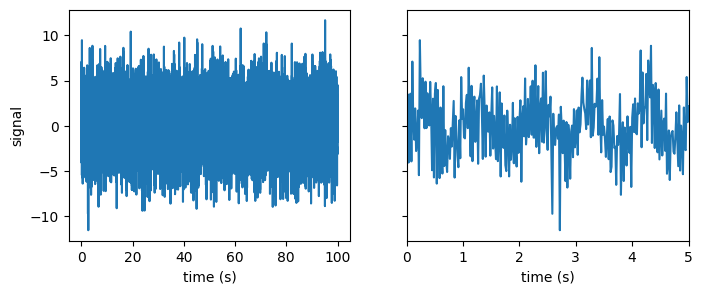

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(8, 3), sharey=True)
axes[0].plot(t, f_t)
axes[0].set_xlabel("time (s)")
axes[0].set_ylabel("signal")
axes[1].plot(t, f_t)
axes[1].set_xlim(0, 5)
axes[1].set_xlabel("time (s)")

In [7]:
 F = fftpack.fft(f_t)

In [8]:
 f = fftpack.fftfreq(N, 1.0/f_s)

In [9]:
 mask = np.where(f >= 0)

<>:4: SyntaxWarning: invalid escape sequence '\l'
<>:4: SyntaxWarning: invalid escape sequence '\l'
/var/folders/ks/l5k0stm95w5b5kn73hwp_8hc0000gn/T/ipykernel_72394/3344888445.py:4: SyntaxWarning: invalid escape sequence '\l'
  axes[0].set_ylabel("$\log(|F|)$", fontsize=14)


Text(0, 0.5, '$|F|/N$')

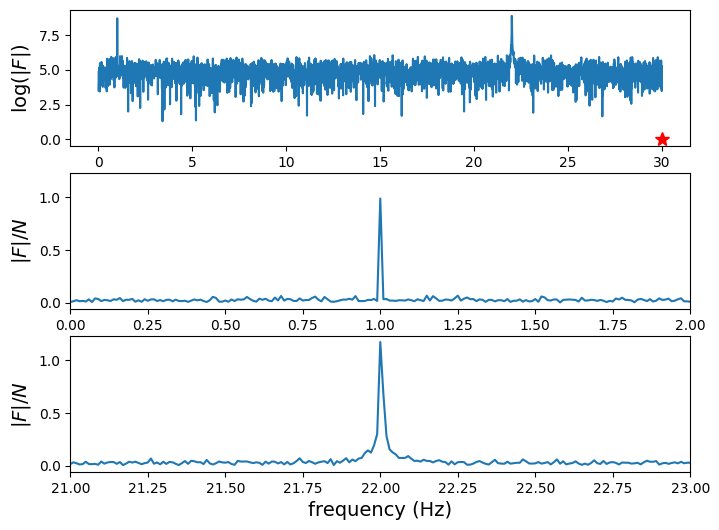

In [10]:
fig, axes = plt.subplots(3, 1, figsize=(8, 6))
axes[0].plot(f[mask], np.log(abs(F[mask])), label="real")
axes[0].plot(B, 0, "r*", markersize=10)
axes[0].set_ylabel("$\log(|F|)$", fontsize=14)
axes[1].plot(f[mask], abs(F[mask]) / N, label="real")
axes[1].set_xlim(0, 2)
axes[1].set_ylabel("$|F|/N$", fontsize=14)
axes[2].plot(f[mask], abs(F[mask]) / N, label="real")
axes[2].set_xlim(21, 23)
axes[2].set_xlabel("frequency (Hz)", fontsize=14)
axes[2].set_ylabel("$|F|/N$", fontsize=14)

Frequency-Domain Filter

In [11]:
 F_filtered = F * (abs(f) < 2)
 f_t_filtered = fftpack.ifft(F_filtered)

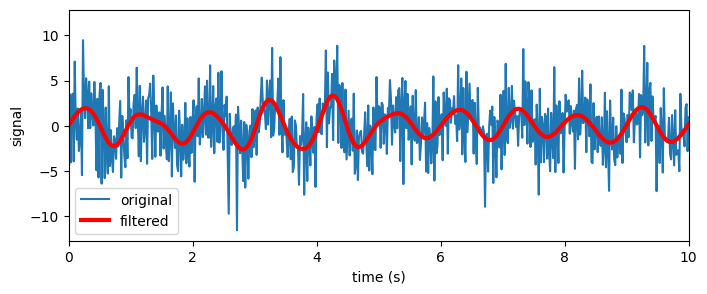

In [12]:
fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(t, f_t, label="original")
ax.plot(t, f_t_filtered.real, color="red", lw=3, label="filtered")
ax.set_xlim(0, 10)
ax.set_xlabel("time (s)")
ax.set_ylabel("signal")
ax.legend()

Windowing

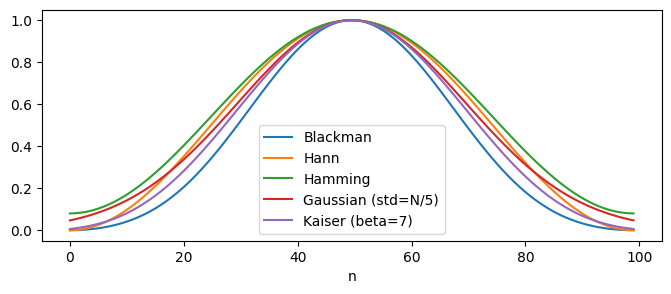

In [13]:
fig, ax = plt.subplots(1, 1, figsize=(8, 3))
N = 100
ax.plot(signal.windows.blackman(N), label="Blackman")
ax.plot(signal.windows.hann(N), label="Hann")
ax.plot(signal.windows.hamming(N), label="Hamming")
ax.plot(signal.windows.gaussian(N, N / 5), label="Gaussian (std=N/5)")
ax.plot(signal.windows.kaiser(N, 7), label="Kaiser (beta=7)")
ax.set_xlabel("n")
ax.legend(loc=0)

In [14]:
df = pd.read_csv(
    "temperature_outdoor_2014.tsv", delimiter="\t", names=["time", "temperature"]
)
df.time = (
    pd.to_datetime(df.time.values, unit="s")
    .tz_localize("UTC")
    .tz_convert("Europe/Stockholm")
)
df = df.set_index("time")
df = df.resample("h").ffill()
df = df[(df.index >= "2014-04-01") & (df.index < "2014-06-01")].dropna()

In [15]:
# time = df.index.astype('int64')/1.0e9
# temperature = df.temperature.values

temperature = df["temperature"].values
time = np.arange(len(temperature)) * 3600.0

In [16]:
 window = signal.windows.blackman(len(temperature))

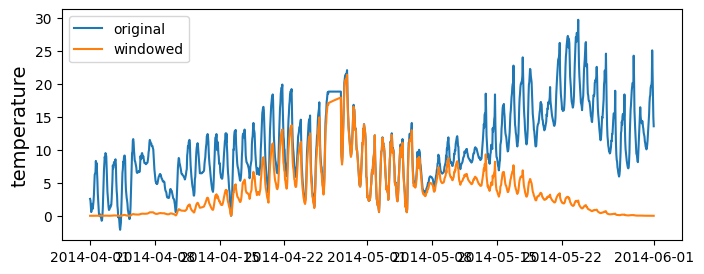

In [17]:
temperature_windowed = temperature * window

# temperature_windowed = temperature * window
fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(df.index, temperature, label="original")
ax.plot(df.index, temperature_windowed, label="windowed")
ax.set_ylabel("temperature", fontsize=14)
ax.legend(loc=0)

In [18]:
data_fft_windowed = fftpack.fft(temperature_windowed)
f = fftpack.fftfreq(len(temperature), time[1] - time[0])

Text(0.5, 0, 'frequency (Hz)')

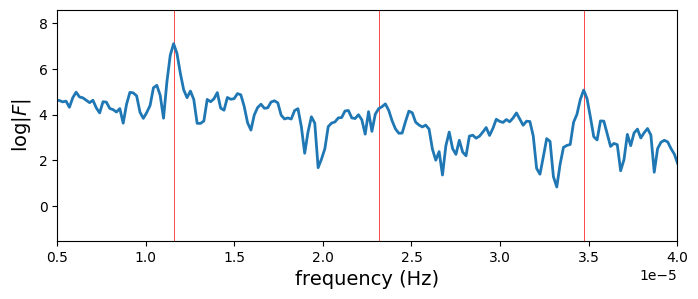

In [19]:
mask = f > 0
fig, ax = plt.subplots(figsize=(8, 3))
ax.set_xlim(0.000005, 0.00004)
ax.axvline(1.0 / 86400, color="r", lw=0.5)
ax.axvline(2.0 / 86400, color="r", lw=0.5)
ax.axvline(3.0 / 86400, color="r", lw=0.5)
ax.plot(f[mask], np.log(abs(data_fft_windowed[mask])), lw=2)
ax.set_ylabel("$\\log|F|$", fontsize=14)
ax.set_xlabel("frequency (Hz)", fontsize=14)

Spectrogram

In [20]:
 sample_rate, data = io.wavfile.read("guitar.wav")

In [21]:
sample_rate

44100

In [22]:
data.shape

(1181625, 2)

In [23]:
data = data.mean(axis=1)
data.shape[0] / sample_rate

26.79421768707483

In [24]:
N = int(sample_rate / 2.0)  # half a second -> 22050 samples

In [25]:
f = fftpack.fftfreq(N, 1.0 / sample_rate)
t = np.linspace(0, 0.5, N)
mask = (f > 0) * (f < 1000)

In [26]:
subdata = data[:N]
F = fftpack.fft(subdata)

Text(0.5, 0, 'Frequency (Hz)')

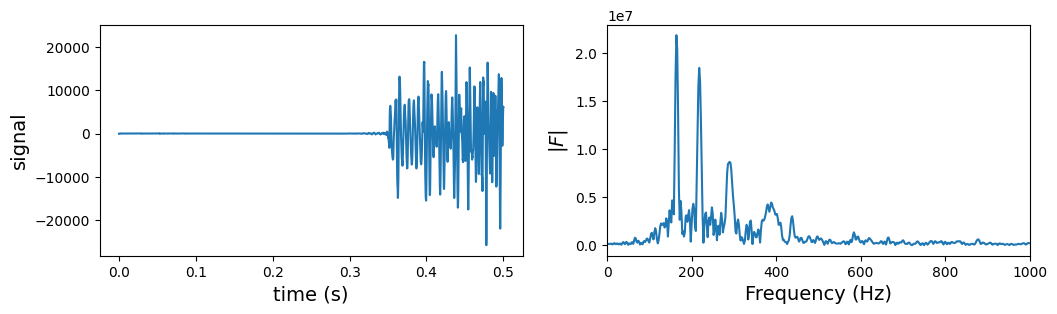

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3))
axes[0].plot(t, subdata)
axes[0].set_ylabel("signal", fontsize=14)
axes[0].set_xlabel("time (s)", fontsize=14)
axes[1].plot(f[mask], abs(F[mask]))
axes[1].set_xlim(0, 1000)
axes[1].set_ylabel("$|F|$", fontsize=14)
axes[1].set_xlabel("Frequency (Hz)", fontsize=14)

In [28]:
n_max = int(data.shape[0] / N)
f_values = np.sum(mask)
spectogram_data = np.zeros((n_max, f_values))

In [29]:
window = signal.windows.blackman(len(subdata))

In [30]:
for n in range(0, n_max):
    subdata = data[(N * n) : (N * (n + 1))]
    F = fftpack.fft(subdata * window)
    spectogram_data[n, :] = np.log(abs(F[mask]))

<>:10: SyntaxWarning: invalid escape sequence '\l'
<>:10: SyntaxWarning: invalid escape sequence '\l'
/var/folders/ks/l5k0stm95w5b5kn73hwp_8hc0000gn/T/ipykernel_72394/3644389190.py:10: SyntaxWarning: invalid escape sequence '\l'
  cb.set_label("$\log|F|$", fontsize=14)


Text(0.5, 0, 'Frequency (Hz)')

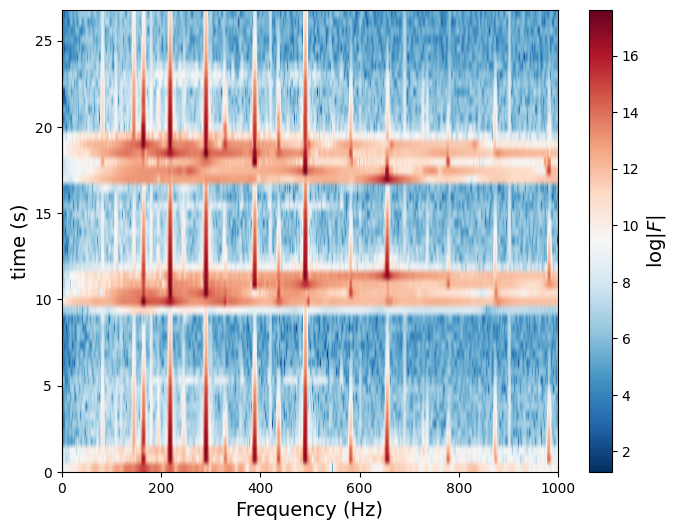

In [31]:
fig, ax = plt.subplots(1, 1, figsize=(8, 6))
p = ax.imshow(
    spectogram_data,
    origin="lower",
    extent=(0, 1000, 0, data.shape[0] / sample_rate),
    aspect="auto",
    cmap=mpl.cm.RdBu_r,
)
cb = fig.colorbar(p, ax=ax)
cb.set_label("$\log|F|$", fontsize=14)
ax.set_ylabel("time (s)", fontsize=14)
ax.set_xlabel("Frequency (Hz)", fontsize=14)

Signal Filters
 - brak kodu w książce ale może jako zqadanie np dać noise reduction? obczaje to czy to bardzo trudne bo wydaje się bardzo ciekawe

Convolution Filters


In [32]:
t = np.linspace(0, T, N)
f_t = signal_samples(t)

f = fftpack.fftfreq(N, t[1] - t[0])
F = fftpack.fft(f_t)
f_t_filtered = fftpack.ifft(F * (abs(f) < 2))

H = abs(f) < 2
h = fftpack.fftshift(fftpack.ifft(H))
f_t_filtered_conv = signal.convolve(f_t, h, mode="same")

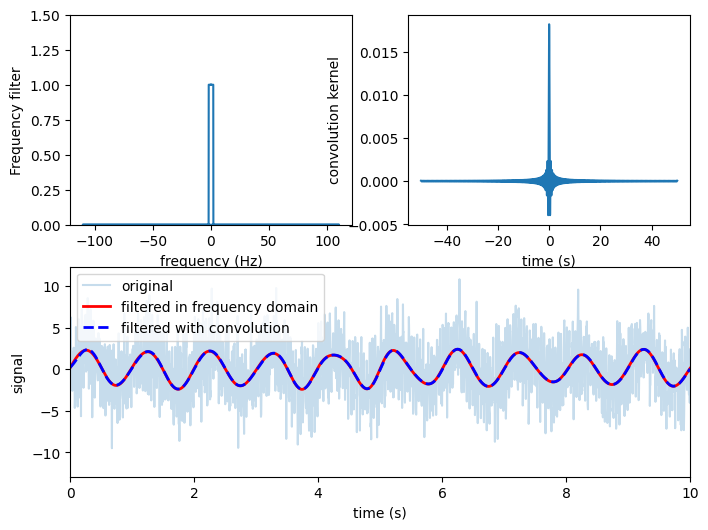

In [33]:
In [63]: fig = plt.figure(figsize=(8, 6))
...: ax = plt.subplot2grid((2,2), (0,0))
...: ax.plot(f, H)
...: ax.set_xlabel("frequency (Hz)")
...: ax.set_ylabel("Frequency filter")
...: ax.set_ylim(0, 1.5)
...: ax = plt.subplot2grid((2,2), (0,1))
...: ax.plot(t - t[-1]/2.0, h.real)
...: ax.set_xlabel("time (s)")
...: ax.set_ylabel("convolution kernel")
...: ax = plt.subplot2grid((2,2), (1,0), colspan=2)
...: ax.plot(t, f_t, label='original', alpha=0.25)
...: ax.plot(t, f_t_filtered.real, 'r', lw=2, label='filtered in frequency domain')
...: ax.plot(t, f_t_filtered_conv.real, 'b--', lw=2, label='filtered with convolution')
...: ax.set_xlim(0, 10)
...: ax.set_xlabel("time (s)")
...: ax.set_ylabel("signal")
...: ax.legend(loc=2)

FIR and IIR Filters


In [34]:
n = 101
f_s = 1 / 3600
nyq = f_s / 2
b = signal.firwin(n, cutoff=nyq / 12, fs=f_s, window="hamming")

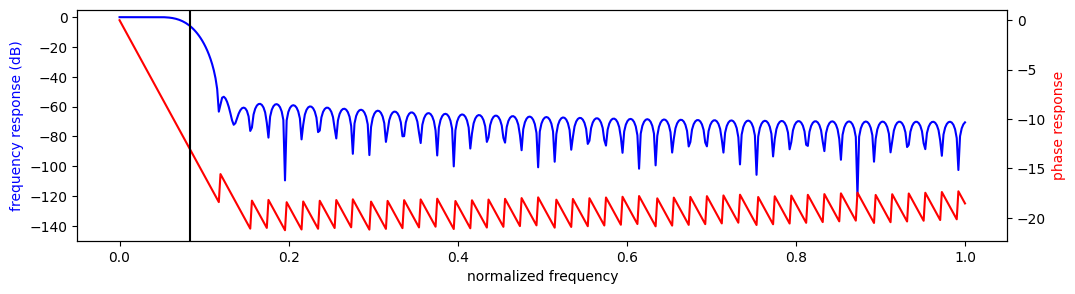

In [35]:
f, h = signal.freqz(b)
fig, ax = plt.subplots(1, 1, figsize=(12, 3))
h_ampl = 20 * np.log10(abs(h))
h_phase = np.unwrap(np.angle(h))
ax.plot(f / max(f), h_ampl, "b")
ax.set_ylim(-150, 5)
ax.set_ylabel("frequency response (dB)", color="b")
ax.set_xlabel(r"normalized frequency")
ax = ax.twinx()
ax.plot(f / max(f), h_phase, "r")
ax.set_ylabel("phase response", color="r")
ax.axvline(1.0 / 12, color="black")

In [36]:
 temperature_filt = signal.lfilter(b, 1, temperature)

In [37]:
temperature_median_filt = signal.medfilt(temperature, 25)

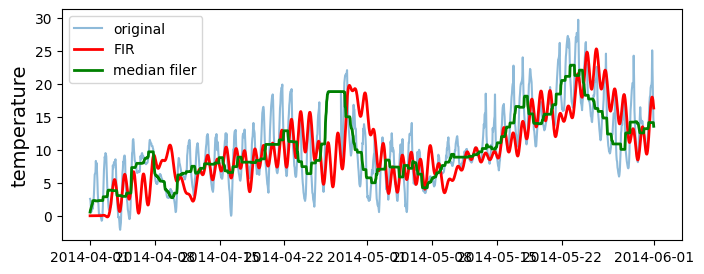

In [38]:
fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(df.index, temperature, label="original", alpha=0.5)
ax.plot(df.index, temperature_filt, color="red", lw=2, label="FIR")
ax.plot(df.index, temperature_median_filt, color="green", lw=2, label="median filer")
ax.set_ylabel("temperature", fontsize=14)
ax.legend(loc=0)

In [39]:
b, a = signal.butter(2, 7 / 365.0, btype="high")

In [40]:
b

array([ 0.95829139, -1.91658277,  0.95829139])

In [41]:
a

array([ 1.        , -1.91484241,  0.91832314])

In [42]:
 temperature_iir = signal.lfilter(b, a, temperature)

In [43]:
 temperature_filtfilt = signal.filtfilt(b, a, temperature)

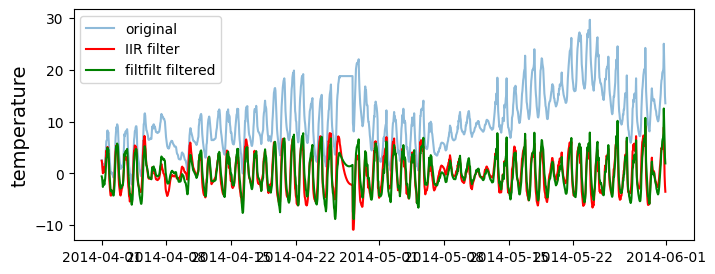

In [44]:
fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(df.index, temperature, label="original", alpha=0.5)
ax.plot(df.index, temperature_iir, color="red", label="IIR filter")
ax.plot(df.index, temperature_filtfilt, color="green", label="filtfilt filtered")
ax.set_ylabel("temperature", fontsize=14)
ax.legend(loc=0)

In [45]:
b = np.zeros(10000)
b[0] = b[-1] = 1
b /= b.sum()
data_filt = signal.lfilter(b, 1, data, axis=0)

In [46]:
# io.wavfile.write("guitar-echo.wav", sample_rate, np.vstack([data_filt, data_filt]).T.astype(np.int16))
io.wavfile.write("guitar-echo.wav", sample_rate, data_filt.astype(np.int16))